# 11 · Frameworks de IA: PyTorch y TensorFlow lado a lado

Casi toda la investigación y producción de IA moderna se ejecuta sobre dos frameworks de Python: **PyTorch**
(Meta, hoy la PyTorch Foundation) y **TensorFlow** con su API de alto nivel **Keras** (Google). Los dos hacen las
mismas tres cosas: tensores en CPU o GPU, diferenciación automática y construir y entrenar redes neuronales.
Este módulo resuelve un mismo problema con ambos, línea a línea, para que se vean las diferencias.

> Nuestro curso gratuito *Redes Neuronales 1001* construye estas ideas desde cero; aquí el foco son los propios
> frameworks.

**Aprenderás**
1. Tensores y diferenciación automática en cada framework
2. El mismo modelo entrenado en ambos: el bucle explícito de PyTorch y el `fit` de Keras
3. Comparar exactitud y velocidad de forma justa
4. Guardar, cargar y exportar modelos
5. Cómo elegir, y el resto del ecosistema (JAX, Hugging Face, ONNX)

## 1. Tensores y gradientes
Los dos frameworks registran las operaciones sobre tensores y pueden derivar a través de ellas. Comprobación: la
derivada de $f(x) = x^3 + 2x$ en $x = 2$ es $3 \cdot 2^2 + 2 = 14$.

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")       # arranque de TensorFlow más silencioso
import numpy as np
import torch
import tensorflow as tf

print("PyTorch", torch.__version__, "| TensorFlow", tf.__version__)

x_pt = torch.tensor(2.0, requires_grad=True)
f_pt = x_pt ** 3 + 2 * x_pt
f_pt.backward()                                            # PyTorch: los gradientes se acumulan en .grad
print("PyTorch    df/dx =", x_pt.grad.item())

x_tf = tf.Variable(2.0)
with tf.GradientTape() as tape:                             # TensorFlow: se graba dentro de una "cinta"
    f_tf = x_tf ** 3 + 2 * x_tf
print("TensorFlow df/dx =", tape.gradient(f_tf, x_tf).numpy())

a = np.arange(6, dtype=np.float32).reshape(2, 3)
print(torch.from_numpy(a) @ torch.ones(3), tf.linalg.matvec(tf.constant(a), tf.ones(3)).numpy())

I0000 00:00:1792318374.940065 1036723 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792318378.580599 1036723 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


PyTorch 2.14.1+cpu | TensorFlow 2.21.0
PyTorch    df/dx = 14.0
TensorFlow df/dx = 14.0
tensor([ 3., 12.]) [ 3. 12.]


## 2. La tarea
Dígitos manuscritos (8×8 píxeles, 1.797 imágenes, incluidos en scikit-learn), divididos una sola vez para que
ambos frameworks vean exactamente las mismas imágenes de entrenamiento y de prueba.

(1347, 8, 8) (450, 8, 8)


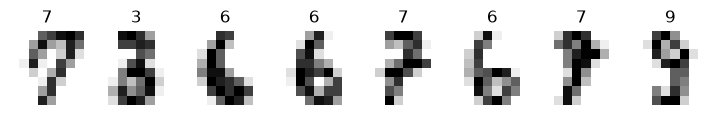

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)               # escalar los píxeles a [0, 1]
y = digits.target.astype(np.int64)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(X_train.shape, X_test.shape)

fig, axes = plt.subplots(1, 8, figsize=(9, 1.4))
for ax, img, label in zip(axes, X_train, y_train):
    ax.imshow(img, cmap="gray_r"); ax.set_title(label); ax.axis("off")
plt.show()

## 3. PyTorch: definir un módulo y escribir el bucle
PyTorch hace explícito el bucle de entrenamiento. Más código, pero cada paso es visible y fácil de adaptar, una
de las razones por las que domina la investigación.

In [3]:
torch.manual_seed(0)
EPOCHS, BATCH, LR = 30, 64, 1e-3

class SmallCNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.features = torch.nn.Sequential(
            torch.nn.Conv2d(1, 16, 3, padding=1), torch.nn.ReLU(), torch.nn.MaxPool2d(2),   # 8x8 -> 4x4
            torch.nn.Conv2d(16, 32, 3, padding=1), torch.nn.ReLU(),
        )
        self.head = torch.nn.Sequential(torch.nn.Flatten(), torch.nn.Linear(32 * 4 * 4, 64), torch.nn.ReLU(),
                                        torch.nn.Dropout(0.2), torch.nn.Linear(64, 10))
    def forward(self, x):
        return self.head(self.features(x))

pt_model = SmallCNN()
optimizer = torch.optim.Adam(pt_model.parameters(), lr=LR)
loss_fn = torch.nn.CrossEntropyLoss()
Xtr, ytr = torch.from_numpy(X_train[:, None]), torch.from_numpy(y_train)      # (N, 1, 8, 8): canales primero
Xte, yte = torch.from_numpy(X_test[:, None]), torch.from_numpy(y_test)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr, ytr), batch_size=BATCH, shuffle=True)

pt_history, t0 = [], time.perf_counter()
for epoch in range(EPOCHS):
    pt_model.train()
    for xb, yb in loader:
        optimizer.zero_grad()                 # 1. poner a cero los gradientes
        loss = loss_fn(pt_model(xb), yb)      # 2. pasada hacia delante
        loss.backward()                       # 3. retropropagar
        optimizer.step()                      # 4. actualizar los pesos
    pt_model.eval()
    with torch.no_grad():
        pt_history.append((pt_model(Xte).argmax(1) == yte).float().mean().item())
pt_time = time.perf_counter() - t0
print(f"PyTorch: exactitud en prueba {pt_history[-1]:.3f} tras {EPOCHS} épocas, {pt_time:.1f} s, "
      f"{sum(p.numel() for p in pt_model.parameters()):,} parámetros")

PyTorch: exactitud en prueba 0.971 tras 30 épocas, 5.1 s, 38,282 parámetros


## 4. TensorFlow / Keras: declarar el modelo y llamar a `fit`
La misma arquitectura. Keras oculta el bucle tras `compile` y `fit`, que es conciso y difícil de equivocar.
(También se puede escribir un bucle propio con `GradientTape` cuando hace falta.)

In [4]:
tf.keras.utils.set_random_seed(0)
tf_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8, 8, 1)),                                   # canales al final
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"), tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.Flatten(), tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(10),
])
tf_model.compile(optimizer=tf.keras.optimizers.Adam(LR),
                 loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
t0 = time.perf_counter()
hist = tf_model.fit(X_train[..., None], y_train, validation_data=(X_test[..., None], y_test),
                    epochs=EPOCHS, batch_size=BATCH, verbose=0)
tf_time = time.perf_counter() - t0
tf_history = hist.history["val_accuracy"]
print(f"TensorFlow: exactitud en prueba {tf_history[-1]:.3f} tras {EPOCHS} épocas, {tf_time:.1f} s, "
      f"{tf_model.count_params():,} parámetros")

TensorFlow: exactitud en prueba 0.978 tras 30 épocas, 12.0 s, 38,282 parámetros


## 5. Compararlos
Mismos datos, misma arquitectura, mismo optimizador y mismo número de parámetros. Las diferencias en la exactitud
final vienen de la inicialización aleatoria y del barajado, no del framework.

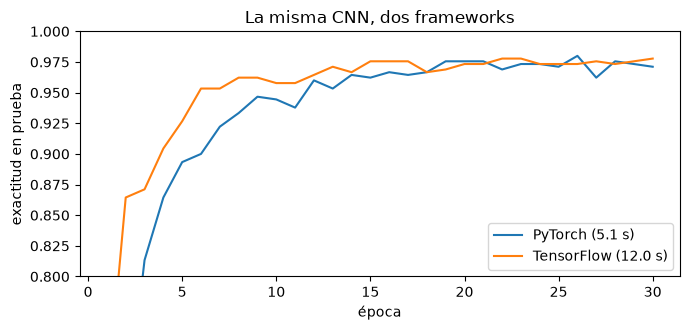

los dos modelos coinciden en el 97.8% de las imágenes de prueba; ambos fallan en la misma imagen: 7


In [5]:
plt.figure(figsize=(7, 3.4))
plt.plot(range(1, EPOCHS + 1), pt_history, label=f"PyTorch ({pt_time:.1f} s)")
plt.plot(range(1, EPOCHS + 1), tf_history, label=f"TensorFlow ({tf_time:.1f} s)")
plt.xlabel("época"); plt.ylabel("exactitud en prueba"); plt.ylim(0.8, 1.0); plt.legend(); plt.title("La misma CNN, dos frameworks")
plt.tight_layout(); plt.show()

with torch.no_grad():
    p_pt = pt_model(Xte).argmax(1).numpy()
p_tf = tf_model.predict(X_test[..., None], verbose=0).argmax(1)
print(f"los dos modelos coinciden en el {np.mean(p_pt == p_tf):.1%} de las imágenes de prueba; "
      f"ambos fallan en la misma imagen: {np.sum((p_pt != y_test) & (p_tf != y_test))}")

## 6. Guardar, cargar, exportar

In [6]:
import tempfile
d = tempfile.mkdtemp()

torch.save(pt_model.state_dict(), os.path.join(d, "cnn.pt"))      # PyTorch: guardar los pesos
restored = SmallCNN(); restored.load_state_dict(torch.load(os.path.join(d, "cnn.pt"))); restored.eval()
with torch.no_grad():
    print("PyTorch, recarga idéntica:", torch.equal(restored(Xte).argmax(1), pt_model(Xte).argmax(1)))

tf_model.save(os.path.join(d, "cnn.keras"))                         # Keras: arquitectura + pesos en un solo archivo
reloaded = tf.keras.models.load_model(os.path.join(d, "cnn.keras"))
print("Keras, recarga idéntica:", np.array_equal(reloaded.predict(X_test[..., None], verbose=0).argmax(1), p_tf))

print({f: f"{os.path.getsize(os.path.join(d, f)) / 1024:.0f} KB" for f in os.listdir(d)})

PyTorch, recarga idéntica: True


Keras, recarga idéntica: True
{'cnn.pt': '153 KB', 'cnn.keras': '485 KB'}


Para el despliegue, los modelos suelen exportarse a un formato neutral u optimizado: **ONNX** (ambos frameworks,
se ejecuta en cualquier sitio con ONNX Runtime), **TorchScript / torch.export** (PyTorch), **SavedModel** y
**LiteRT** (antes TensorFlow Lite, para móviles y microcontroladores).

## 7. Elegir
| | PyTorch | TensorFlow / Keras |
|---|---|---|
| estilo | explícito, pythónico, ejecución inmediata por defecto | `fit` de alto nivel, compilación de grafos con `tf.function` |
| donde más destaca | investigación, arquitecturas nuevas, la mayoría de los artículos nuevos y el trabajo con LLM | flujos de producción (TFX), móviles y dispositivos embebidos (LiteRT), TPU |
| ecosistema | Hugging Face Transformers, PyTorch Lightning, torchvision | Keras, TensorFlow Serving, TF.js en el navegador |
| nota | | Keras 3 también puede usar PyTorch o JAX como motor |

El panorama más amplio: **JAX** (Google; API de NumPy con transformaciones componibles `grad`, `jit`, `vmap`,
popular en investigación a gran escala), **Hugging Face** (modelos preentrenados y datasets para todos los
frameworks), **scikit-learn** (aprendizaje automático clásico, a menudo el primer modelo adecuado), **ONNX
Runtime** (inferencia rápida en cualquier sitio).

## Ejercicios
1. Escribe el entrenamiento del modelo de Keras con un bucle propio usando `tf.GradientTape`, imitando el bucle de PyTorch.
2. Quita las capas convolucionales y usa solo capas densas. ¿Cuánta exactitud se pierde?
3. Exporta el modelo de PyTorch a ONNX (`torch.onnx.export`) y ejecútalo con `onnxruntime`.